# Trade the gap between cousins — Stage 3: pairs mean reversion in FX and commodities

**Project:** Mean reversion across FX and commodities · **Stage 3 of 4** · Heritage Edge

### Where Stages 1 and 2 left us
* **Stage 1:** betting against every daily move drowned in trading costs.
* **Stage 2:** betting only against *big* moves failed too — big moves are usually **news**, and news doesn't reverse.

### The Stage 3 idea, explained simply
Picture a person walking a dog on a lead. Both wander about unpredictably — you can't guess where either will be tomorrow. But **the distance between them can't grow forever**: when the lead gets tight, one of them gets pulled back.

Some markets are tied together like that, because the same forces drive them:

| Pair | Why they're tied |
|---|---|
| **Gold & silver** | Both precious metals, bought for similar reasons |
| **Brent & WTI oil** | The same product (crude oil) priced in two places |
| **AUDUSD & NZDUSD** | Two neighbouring commodity-exporting economies, both priced against the US dollar |

When news arrives, it usually hits **both** cousins — so the news cancels out in the **gap** between them. What's left in the gap is more likely to be noise that snaps back. So instead of betting on one price, we bet on **the gap closing**:

* Gap unusually **wide** → sell the one that's too high, buy the one that's too low.
* Gap back to **normal** → close both.

This is called **pairs trading** or **relative value**, and it's how trading desks really use mean reversion.

> Same honesty rules as before: settings are chosen **before** looking at results, and only the unseen test period counts.

## 1. Setup

In [14]:
%pip install -q yfinance pandas numpy matplotlib jinja2

Note: you may need to restart the kernel to use updated packages.


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (11, 4)

## 2. Settings — all chosen in advance

| Setting | What it means |
|---|---|
| `BETA_WINDOW` | Days used to work out how much of one cousin balances the other (one year) |
| `Z_WINDOW` | Days used to judge what a "normal" gap looks like (about three months) |
| `ENTRY_Z` | Open a trade when the gap is more than 2 normal wobbles away from usual |
| `EXIT_Z` | Close it when the gap is back within 0.5 wobbles of usual |
| `TARGET_VOL`, `MAX_LEVERAGE` | Same risk sizing as Stage 2 |

These are standard textbook values. We **don't** tune them on the data — that's how we avoid fooling ourselves.

Costs are one-way, per unit traded, in basis points (silver and the oil pair are a bit pricier to trade than gold or the big currencies).

In [16]:
PAIRS = {
    # pair name          : (leg A, leg B)
    "Gold vs silver"     : ("Gold",   "Silver"),
    "Brent vs WTI"       : ("Brent",  "WTI oil"),
    "AUDUSD vs NZDUSD"   : ("AUDUSD", "NZDUSD"),
}
TICKERS = {"Gold": "GC=F", "Silver": "SI=F", "Brent": "BZ=F", "WTI oil": "CL=F",
           "AUDUSD": "AUDUSD=X", "NZDUSD": "NZDUSD=X"}
COST_BPS = {"Gold": 1.5, "Silver": 3.0, "Brent": 2.5, "WTI oil": 2.5, "AUDUSD": 0.7, "NZDUSD": 1.0}

START, END   = "2012-01-01", "2026-10-01"
TRADING_DAYS = 252
TRAIN_SHARE  = 0.75

BETA_WINDOW  = 252
Z_WINDOW     = 60
ENTRY_Z      = 2.0
EXIT_Z       = 0.5
TARGET_VOL   = 0.10
MAX_LEVERAGE = 3.0

## 3. Download, clean and line up the prices

Same cleaning as before. One extra step: the two cousins must be compared **on the same days**, so we keep only dates where both have a price.

> **Heads-up on Brent vs WTI:** Yahoo stitches futures contracts together, and Brent and WTI swap to their next contract on different dates. That can create a fake jump in the gap. Stage 4 handles this properly; for now, treat the oil pair's results with extra caution.

In [17]:
def download_close(ticker, start, end):
    data = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=False)
    if data.empty:
        raise ValueError(f"No data came back for {ticker}. Check the ticker or your internet.")
    close = data["Close"]
    return close.iloc[:, 0] if isinstance(close, pd.DataFrame) else close

def clean(close, name):
    s = close.dropna()
    s = s[~s.index.duplicated(keep="last")].sort_index()
    bad = s[s <= 0]
    if len(bad):
        print(f"{name}: removed {len(bad)} day(s) with price <= 0 -> {list(bad.index.date)}")
    s = s[s > 0]
    big = np.log(s).diff().abs()
    big = big[big > 0.10]
    if len(big):
        print(f"{name}: {len(big)} day(s) moved more than 10% -> {list(big.index.date)}")
    return s.rename(name)

prices = {name: clean(download_close(t, START, END), name) for name, t in TICKERS.items()}

pair_px = {}
for pair, (a, b) in PAIRS.items():
    pair_px[pair] = pd.concat([prices[a], prices[b]], axis=1, join="inner")
    print(f"{pair}: {len(pair_px[pair])} shared days, {pair_px[pair].index.min().date()} to {pair_px[pair].index.max().date()}")

Gold: 1 day(s) moved more than 10% -> [datetime.date(2026, 1, 30)]
Silver: 11 day(s) moved more than 10% -> [datetime.date(2013, 4, 15), datetime.date(2016, 11, 14), datetime.date(2020, 3, 16), datetime.date(2020, 8, 11), datetime.date(2020, 9, 21), datetime.date(2021, 1, 8), datetime.date(2021, 2, 2), datetime.date(2025, 12, 30), datetime.date(2026, 1, 26), datetime.date(2026, 1, 30), datetime.date(2026, 2, 12)]
Brent: 18 day(s) moved more than 10% -> [datetime.date(2014, 11, 28), datetime.date(2016, 2, 12), datetime.date(2019, 9, 16), datetime.date(2020, 3, 9), datetime.date(2020, 3, 16), datetime.date(2020, 3, 18), datetime.date(2020, 3, 19), datetime.date(2020, 4, 2), datetime.date(2020, 4, 3), datetime.date(2020, 4, 21), datetime.date(2020, 4, 30), datetime.date(2020, 5, 5), datetime.date(2021, 11, 26), datetime.date(2022, 3, 9), datetime.date(2026, 3, 10), datetime.date(2026, 3, 23), datetime.date(2026, 4, 1), datetime.date(2026, 4, 8)]
WTI oil: removed 1 day(s) with price <= 0 -

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsne

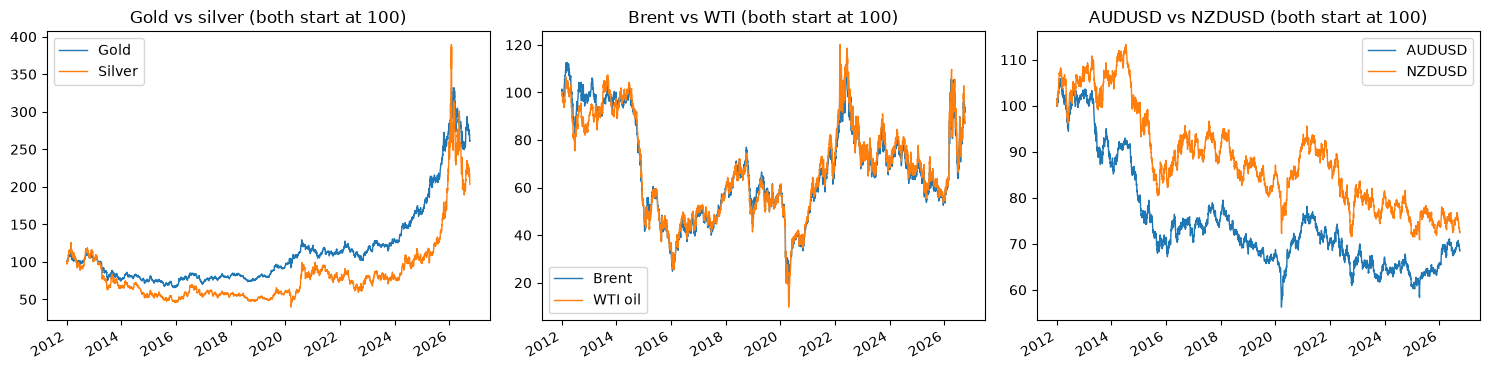

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (pair, px) in zip(axes, pair_px.items()):
    (px / px.iloc[0] * 100).plot(ax=ax, lw=1)
    ax.set_title(f"{pair} (both start at 100)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

Look at how closely each pair travels together. The dog and its owner should wander together, never drifting apart for good.

## 4. Step 1 — Is the lead real? (training period only)

Before trading a gap, we check that it really does get pulled back. We use only the **training period** (first 75%, about 2012–2022).

### Building the gap
First we find the balance between the two cousins — how much of B moves like one unit of A. This number is the **hedge ratio**, $\beta$, found by fitting a straight line through the log prices:

$$\ln A_t \approx \alpha + \beta \ln B_t$$

The **gap** (also called the *spread*) is whatever that line doesn't explain:

$$\text{gap}_t = \ln A_t - \alpha - \beta \ln B_t$$

> **Everyday example:** if silver moves about twice as much as gold, you'd hold about half as much silver as gold so the two balance out. That "half" is $\beta$.

### Does the gap get pulled back?
We ask: when the gap is wide, does it shrink the next day? We fit:

$$\Delta\text{gap}_t = a + b \cdot \text{gap}_{t-1}$$

* $b < 0$ means a wide gap tends to shrink — the lead pulls back.
* The **t-stat of $b$** tells us whether that pull is real. Because we built the gap to look as tidy as possible (we *chose* $\beta$ to fit), the bar is higher than ±2: we need **below −3.34** (the standard *Engle–Granger* 5% cut-off). This whole check is called a **cointegration test**.

### How fast does it snap back?
The **half-life** is how many days it usually takes for a gap to close halfway:

$$\text{half-life} = -\frac{\ln 2}{\ln(1 + b)}$$

A half-life of a few weeks is great for trading. A half-life of a year means you'd be waiting a very long time — and paying to hold the trade.

In [19]:
def fit_line(y, x):
    X = np.column_stack([np.ones(len(x)), x])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ coef
    se = np.sqrt((resid @ resid) / (len(y) - 2) * np.linalg.inv(X.T @ X).diagonal())
    return coef, coef / se, resid       # [intercept, slope], t-stats, leftovers

tie_rows = {}
for pair, px in pair_px.items():
    a, b = px.columns
    train = np.log(px.iloc[: int(len(px) * TRAIN_SHARE)])
    (alpha, beta), _, gap = fit_line(train[a].values, train[b].values)
    (_, b_coef), (_, b_t), _ = fit_line(np.diff(gap), gap[:-1])
    tie_rows[pair] = {
        "hedge ratio (beta)":   beta,
        "pull-back b":          b_coef,
        "t-stat of b":          b_t,
        "passes (t < -3.34)?":  "yes" if b_t < -3.34 else "no",
        "half-life (days)":     -np.log(2) / np.log(1 + b_coef) if b_coef < 0 else np.inf,
    }
pd.DataFrame(tie_rows).T

,hedge ratio (beta),pull-back b,t-stat of b,passes (t < -3.34)?,half-life (days)
Gold vs silver,0.5342,-0.0010,-1.0229,no,675.2363
Brent vs WTI,0.9986,-0.0331,-6.8212,yes,20.5787
AUDUSD vs NZDUSD,1.3099,-0.0062,-3.4172,yes,111.1645


**How to read this:** a pair that passes has a t-stat below −3.34 and a half-life short enough to trade (ideally under about 60 days, since we judge "normal" over 60 days). A pair that fails isn't necessarily useless — over shorter windows the lead may still hold — but it's a warning that the tie can stretch for a long time.

## 5. Step 2 — Measure the gap day by day, without peeking

For the strategy we rebuild the gap **every day using only past data**:
* $\beta$ is re-estimated each day from the previous `BETA_WINDOW` (252) days.
* The gap is compared with its own average and wobble over the previous `Z_WINDOW` (60) days, giving a z-score — the same ruler as Stage 2:

$$z_t = \frac{\text{gap}_t - \text{average gap (past 60 days)}}{\text{wobble of the gap (past 60 days)}}$$

$z = +2$: the gap is unusually **wide** (A expensive vs B). $z = -2$: unusually **narrow** (A cheap vs B).

> **One subtle detail:** $\beta$ changes a little every day. If we compared today's gap (built with today's $\beta$) with past gaps built with *older* $\beta$s, we'd be measuring the change in $\beta$, not the change in the gap — like measuring a table with a ruler that keeps stretching. So each day we rebuild the past 60 days of the gap with **today's** $\beta$ before comparing.

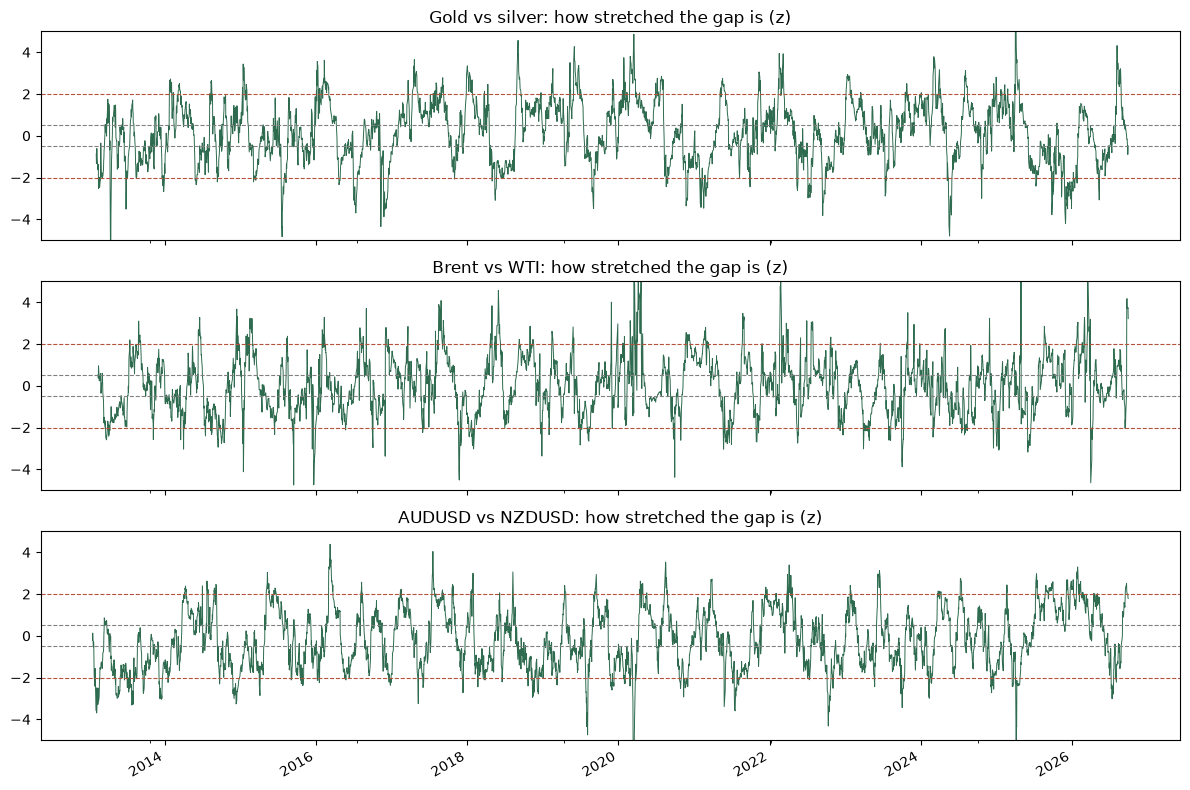

In [20]:
def make_pair_frame(px):
    a, b = px.columns
    df = pd.DataFrame(index=px.index)
    la, lb = np.log(px[a]), np.log(px[b])
    df["ret_a"], df["ret_b"] = px[a].pct_change(), px[b].pct_change()
    df["beta"] = (la.rolling(BETA_WINDOW).cov(lb) / lb.rolling(BETA_WINDOW).var()).shift(1)   # past data only
    beta = df["beta"]
    df["gap"]  = la - beta * lb
    # Past 60 days of the gap, rebuilt with TODAY's beta so we compare like with like
    m_a, m_b = la.rolling(Z_WINDOW).mean().shift(1), lb.rolling(Z_WINDOW).mean().shift(1)
    v_a, v_b = la.rolling(Z_WINDOW).var().shift(1),  lb.rolling(Z_WINDOW).var().shift(1)
    c_ab     = la.rolling(Z_WINDOW).cov(lb).shift(1)
    mean_ = m_a - beta * m_b
    std_  = np.sqrt(v_a + beta**2 * v_b - 2 * beta * c_ab)
    df["z"] = (df["gap"] - mean_) / std_
    df["gap_ret"] = df["ret_a"] - df["beta"] * df["ret_b"]                  # daily return of "A minus beta*B"
    df["gap_vol"] = df["gap_ret"].rolling(20).std().shift(1)
    df["size"] = (TARGET_VOL / np.sqrt(TRADING_DAYS) / df["gap_vol"]).clip(upper=MAX_LEVERAGE)
    return df.dropna()

frames = {pair: make_pair_frame(px) for pair, px in pair_px.items()}

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, (pair, df) in zip(axes, frames.items()):
    df["z"].plot(ax=ax, color="#2E6B4F", lw=0.7)
    for lvl, c in [(ENTRY_Z, "#B5523B"), (-ENTRY_Z, "#B5523B"), (EXIT_Z, "grey"), (-EXIT_Z, "grey")]:
        ax.axhline(lvl, color=c, lw=0.8, ls="--")
    ax.set_title(f"{pair}: how stretched the gap is (z)"); ax.set_ylim(-5, 5); ax.set_xlabel("")
plt.tight_layout(); plt.show()

Red dashed lines = **entry** (±2). Grey dashed lines = **exit** (±0.5). Every time the green line pokes past a red line, the strategy opens a trade, and it closes once the line comes back between the grey lines.

## 6. The pairs strategy

### The rule
| Situation | What we do |
|---|---|
| $z$ rises **above +2** | Gap too wide: **sell A, buy B** (bet the gap shrinks) |
| $z$ falls **below −2** | Gap too narrow: **buy A, sell B** (bet the gap widens) |
| In a trade and $z$ comes back **within ±0.5** | Close both legs |
| Otherwise | Keep doing what we're doing |

We decide using yesterday's $z$ and trade at yesterday's close, as in earlier stages. Each leg is sized so the pair together targets 10% annual volatility:

$$\text{weight}_A = \text{position} \times \text{size}, \qquad \text{weight}_B = -\,\text{position} \times \text{size} \times \beta$$

### Costs
We now pay the spread on **two** markets. Each day:

$$\text{cost}_t = |\Delta \text{weight}_A| \times \text{cost}_A + |\Delta \text{weight}_B| \times \text{cost}_B$$

Because $\beta$ and size change a little each day, we also pay small amounts to keep the hedge balanced while a trade is open — just like a real desk would.

In [21]:
def positions_from_z(z, entry=ENTRY_Z, exit_=EXIT_Z):
    # +1 = long the gap (buy A, sell B), -1 = short the gap, 0 = flat.
    pos, state = np.zeros(len(z)), 0
    for i, v in enumerate(z):
        if np.isnan(v):
            state = 0
        else:
            if state == 1 and v > -exit_:
                state = 0
            elif state == -1 and v < exit_:
                state = 0
            if state == 0:
                if v > entry:
                    state = -1
                elif v < -entry:
                    state = 1
        pos[i] = state
    return pos

def run_pair(df, pair, entry=ENTRY_Z, exit_=EXIT_Z, cost_mult=1.0, delay=0):
    a, b = PAIRS[pair]
    out = df.copy()
    decided = positions_from_z(out["z"].values, entry, exit_)            # decided at each day's close
    out["position"] = pd.Series(decided, index=out.index).shift(1 + delay).fillna(0)
    out["w_a"] =  out["position"] * out["size"]
    out["w_b"] = -out["position"] * out["size"] * out["beta"]
    turn_a = out["w_a"].diff().abs().fillna(out["w_a"].abs())
    turn_b = out["w_b"].diff().abs().fillna(out["w_b"].abs())
    out["cost"] = (turn_a * COST_BPS[a] + turn_b * COST_BPS[b]) / 1e4 * cost_mult
    out["gross_ret"] = out["w_a"] * out["ret_a"] + out["w_b"] * out["ret_b"]
    out["net_ret"] = out["gross_ret"] - out["cost"]
    out["net_equity"] = (1 + out["net_ret"]).cumprod()
    return out

## 7. The scorecard — training period vs unseen test period

Same measures as Stages 1 and 2. Because nothing was tuned, the training numbers are a fair description of 2012–2022 too — but the **test period** is still the result that matters most.

* **Avg days per trade** = how long a typical trade stays open. Compare it with the half-life from section 4.

In [22]:
def t_stat(x):
    x = pd.Series(x).dropna()
    return x.mean() / (x.std() / np.sqrt(len(x))) if len(x) > 1 and x.std() > 0 else np.nan

def scorecard(r):
    ret, position = r["net_ret"], r["position"]
    years = len(ret) / TRADING_DAYS
    equity = (1 + ret).cumprod()
    sd = ret.std()
    direction = np.sign(position)
    opens = ((direction != 0) & (direction != direction.shift(1).fillna(0))).sum()
    return {
        "CAGR":              equity.iloc[-1] ** (1 / years) - 1,
        "Volatility":        sd * np.sqrt(TRADING_DAYS),
        "Sharpe":            ret.mean() / sd * np.sqrt(TRADING_DAYS) if sd > 0 else np.nan,
        "Max drawdown":      (equity / equity.cummax() - 1).min(),
        "Win rate":          (ret[position != 0] > 0).mean(),
        "t-stat":            t_stat(ret),
        "Days in market":    (direction != 0).mean(),
        "Trades / year":     opens / years,
        "Avg days per trade": (direction != 0).sum() / opens if opens else np.nan,
        "Cost drag / year":  r["cost"].sum() / years,
    }

FMT = {"CAGR": "{:.1%}", "Volatility": "{:.1%}", "Max drawdown": "{:.1%}", "Win rate": "{:.1%}",
       "Days in market": "{:.0%}", "Cost drag / year": "{:.2%}", "Sharpe": "{:.2f}", "t-stat": "{:.2f}",
       "Trades / year": "{:.1f}", "Avg days per trade": "{:.1f}"}

results = {pair: run_pair(df, pair) for pair, df in frames.items()}
splits  = {pair: int(len(r) * TRAIN_SHARE) for pair, r in results.items()}

cards = {}
for pair, r in results.items():
    cut = splits[pair]
    cards[(pair, "training (to ~2022)")] = scorecard(r.iloc[:cut])
    cards[(pair, "TEST (unseen)")]       = scorecard(r.iloc[cut:])
pd.DataFrame(cards).T.style.format(FMT, na_rep="—")

In [26]:
r = results["Brent vs WTI"]
opens = r.index[(r["position"] != 0) & (r["position"].shift(1).fillna(0) == 0)]
pd.Series(opens.day).value_counts(bins=[0, 5, 10, 15, 20, 25, 31]).sort_index()

(-0.001, 5.0]    28
(5.0, 10.0]       4
(10.0, 15.0]      8
(15.0, 20.0]     12
(20.0, 25.0]     18
(25.0, 31.0]     13
Name: count, dtype: int64

In [27]:
r = results["Brent vs WTI"].copy()
direction = np.sign(r["position"])
r["trade_id"] = ((direction != 0) & (direction != direction.shift(1).fillna(0))).cumsum()
held = r[direction != 0]
trades = held.groupby("trade_id").agg(opened=("net_ret", lambda x: x.index[0]), pnl=("net_ret", "sum"))
trades["opened"] = pd.to_datetime(trades["opened"])
trades["window"] = np.where(trades["opened"].dt.day.between(6, 15), "mid-month (days 6-15)", "near a roll (days 16-5)")
trades.groupby("window")["pnl"].agg(["count", "mean", "sum"])

,count,mean,sum
window,,,
mid-month (days 6-15),12,-0.0028,-0.0339
near a roll (days 16-5),74,0.0144,1.0677


## 8. Equity curves

£1 invested in each pairs strategy, after costs. The **dashed line** marks where the unseen test period starts.

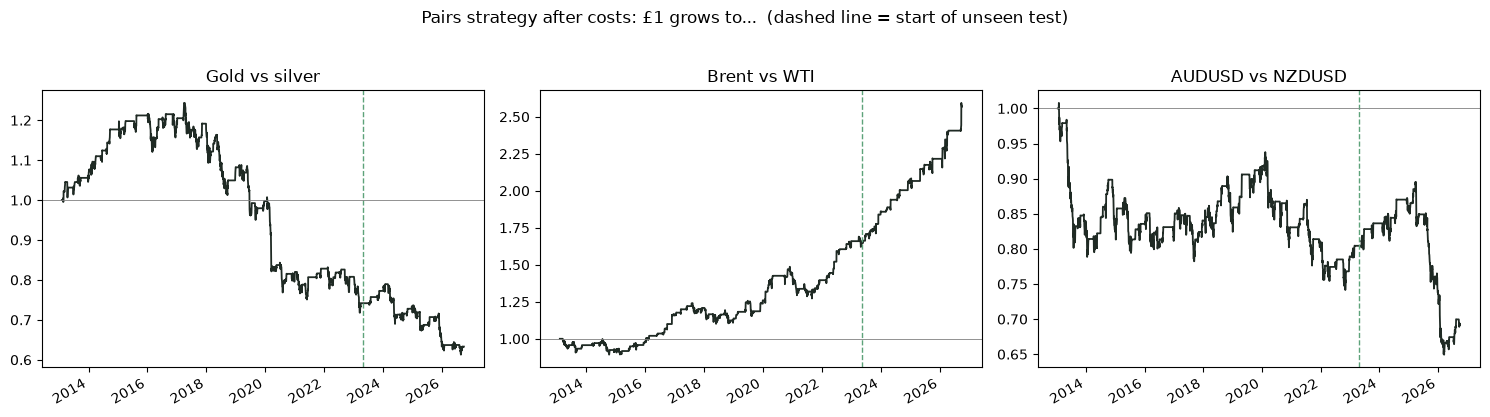

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (pair, r) in zip(axes, results.items()):
    r["net_equity"].plot(ax=ax, color="#1F2A24", lw=1.3)
    ax.axvline(r.index[splits[pair]], color="#5DA37A", ls="--", lw=1)
    ax.axhline(1, color="grey", lw=0.6)
    ax.set_title(pair); ax.set_xlabel("")
plt.suptitle("Pairs strategy after costs: £1 grows to...  (dashed line = start of unseen test)", y=1.03)
plt.tight_layout(); plt.show()

## 9. Stress tests (test period only)

Three checks:
1. **Nearby settings.** We picked entry at 2. If entry at 1.5 or 2.5 gives a completely different answer, the result is fragile. We're *not* choosing a new setting here — just checking the neighbourhood is similar.
2. **Costs** at 0×, 2× and 3× our estimate.
3. **One day late.**

> A real edge looks like a gentle hill: nearby settings give similar results. A fluke looks like a needle: one setting works, its neighbours don't.

In [25]:
stress = {}
for pair, df in frames.items():
    cut = splits[pair]
    test = lambda **kw: scorecard(run_pair(df, pair, **kw).iloc[cut:])["Sharpe"]
    stress[pair] = {
        "entry 1.5":          test(entry=1.5),
        "entry 2.0 (chosen)": test(entry=2.0),
        "entry 2.5":          test(entry=2.5),
        "0x costs":           test(cost_mult=0),
        "2x costs":           test(cost_mult=2),
        "3x costs":           test(cost_mult=3),
        "one day late":       test(delay=1),
    }
pd.DataFrame(stress).T.round(2)

,entry 1.5,entry 2.0 (chosen),entry 2.5,0x costs,2x costs,3x costs,one day late
Gold vs silver,-0.7700,-0.5600,-0.6300,-0.5300,-0.6000,-0.6400,-0.5800
Brent vs WTI,1.9900,1.5000,1.5100,1.6200,1.3900,1.2700,0.9400
AUDUSD vs NZDUSD,-0.4200,-0.5400,-0.5000,-0.4900,-0.5900,-0.6400,-0.3700


## 10. Findings

* **Is the lead real?** Only for the oil pair. Brent vs WTI passed the cointegration test comfortably (t = −6.8), with a one-for-one hedge ratio (1.00), as expected for the same commodity, and a 21-day half-life. AUDUSD vs NZDUSD only just passed (t = −3.42 vs a −3.34 cut-off) with a slow 111-day half-life. Gold vs silver failed (t = −1.0, half-life 675 days), consistent with the gold/silver ratio drifting from about 50 to over 100 during the period.

* **Does it make money after costs?** Only Brent vs WTI: 14.0% a year in the unseen test period, Sharpe 1.50 (t = 2.77), worst drawdown 3.5%, after a positive training period (Sharpe 0.60). Gold vs silver and AUDUSD vs NZDUSD lost money in both periods (test Sharpe −0.56 and −0.54).

* **How does it compare with Stages 1 and 2?** It trades 4–7 times a year instead of 125–165, cutting cost drag from 1.3–6.5% a year to 0.3–1.1%. Brent vs WTI's test Sharpe of 1.50 compares with best single-market test Sharpes of 0.33 (Stage 1) and 0.15 (Stage 2).

* **Is it robust?** For Brent vs WTI, yes: test Sharpe 1.5–2.0 across entry levels of 1.5–2.5, still 1.27 at triple costs, and 0.94 when trading one day late. The other two pairs lost money under every setting, including free trading.

* **Does the trade length match the half-life?** Not for any pair. Gold vs silver and AUDUSD vs NZDUSD trades lasted 26–28 days against half-lives of 675 and 111 days, closing because the 60-day average caught up rather than because the gap closed. Brent vs WTI trades lasted 8.9 days against a 21-day half-life — either fast real snap-backs or an effect of the two futures contracts rolling on different dates.

**Verdict:** Trading the gap between linked markets looked like the breakthrough: Brent vs WTI returned 14% a year on unseen data (Sharpe 1.50, t = 2.77) and passed every stress test. But a closer check showed the edge is a data artefact. Trades cluster just after the two futures contracts’ monthly roll dates (28 of 83 entries on days 1–5, against about 13 expected), and all the profit comes from those trades. The 12 trades opened mid-month, away from any roll, averaged −0.28%. Because Brent and WTI roll on different days, the stitched prices create fake jumps in the gap that “snap back” when the second contract rolls. In real trading, holding actual contracts, those jumps don’t exist. Stage 4 must rebuild the prices before any conclusion about the oil pair can stand.

## What comes next — Stage 4, the honesty layer
* **Futures rolls:** build proper continuous gold, silver, Brent and WTI prices so contract swaps don't create fake gaps.
* **Carry costs:** holding positions overnight in FX costs or pays *swap*; in futures you pay the roll. Include them.
* **Walk-forward testing:** instead of one 75/25 split, re-estimate everything every year and test on the next year, rolling forward.
* **A stop-loss:** if the gap stretches beyond, say, 4 wobbles, the lead may have snapped (the relationship has changed). Close the trade rather than wait.